# 01 EDA - PathSnap (Person A)
Run from the repo root or notebooks/. Raw data in `data/raw/{train,student_test}`.

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
sys.path.insert(0, ".")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, folium
from pathlib import Path
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from src.data.loaders import list_trips, load_trip
from src.features.candidates import prepare, point_segment, build_features
RAW = Path("data/raw")

## 1. Dataset inventory

In [2]:
rows = []
for part in ["train", "student_test"]:
    for tid in list_trips(RAW / part):
        d = RAW / part / f"{tid:08d}"; t = load_trip(RAW / part, tid)
        rows.append(dict(partition=part, trip_id=tid, n_points=len(t["track"]), n_nodes=len(t["nodes"]),
            n_arcs=len(t["arcs"]), route_len=len(t["route"]),
            size_mb=sum(f.stat().st_size for f in d.iterdir()) / 1e6,
            files=len(list(d.iterdir()))))
inv = pd.DataFrame(rows)
print(inv.groupby("partition").agg(trips=("trip_id", "count"), pts_min=("n_points", "min"), pts_med=("n_points", "median"),
      pts_max=("n_points", "max"), pts_total=("n_points", "sum"), MB=("size_mb", "sum")).round(1))
print("files per trip:", inv.files.unique())
inv.head()

              trips  pts_min  pts_med  pts_max  pts_total    MB
partition                                                      
student_test     10      262   1420.0     3958      19160   4.4
train            80      361   1529.0    19313     208417  89.7
files per trip: [4]


,partition,trip_id,n_points,n_nodes,n_arcs,route_len,size_mb,files
0,train,1,1315,88809,165790,525,3.679939,4
1,train,2,7243,7936,16139,262,0.554722,4
2,train,3,821,9138,18028,79,0.385068,4
3,train,4,1064,7350,15499,320,0.333302,4
4,train,5,1045,898,1579,105,0.064110,4


## 2. Missing/invalid GPS values and timestamp gaps

In [3]:
qual = []
for part in ["train", "student_test"]:
    for tid in list_trips(RAW / part):
        tr = load_trip(RAW / part, tid)["track"]; dt = np.diff(tr[:, 2])
        qual.append(dict(partition=part, trip_id=tid, nan=int(np.isnan(tr).sum()),
            bad_lonlat=int(((abs(tr[:, 0]) > 180) | (abs(tr[:, 1]) > 90)).sum()),
            dup_or_back_ts=int((dt <= 0).sum()), pct_1s=(dt == 1).mean() * 100, max_gap_s=dt.max()))
q = pd.DataFrame(qual)
print("total NaN:", q.nan.sum(), "| invalid lon/lat:", q.bad_lonlat.sum(), "| non-increasing timestamps:", q.dup_or_back_ts.sum())
print("overall % of steps that are 1 s:", round(q.pct_1s.mean(), 1))
q.sort_values("pct_1s").head(8)

total NaN: 0 | invalid lon/lat: 0 | non-increasing timestamps: 0
overall % of steps that are 1 s: 94.3


,partition,trip_id,nan,bad_lonlat,dup_or_back_ts,pct_1s,max_gap_s
17,train,22,0,0,0,53.065539,22.0
3,train,4,0,0,0,53.809972,51.0
72,train,90,0,0,0,58.130841,153064.0
32,train,39,0,0,0,58.287293,10.0
38,train,46,0,0,0,62.214286,22.0
19,train,25,0,0,0,69.354839,2.0
64,train,81,0,0,0,71.982625,536.0
61,train,78,0,0,0,75.515818,52810.0


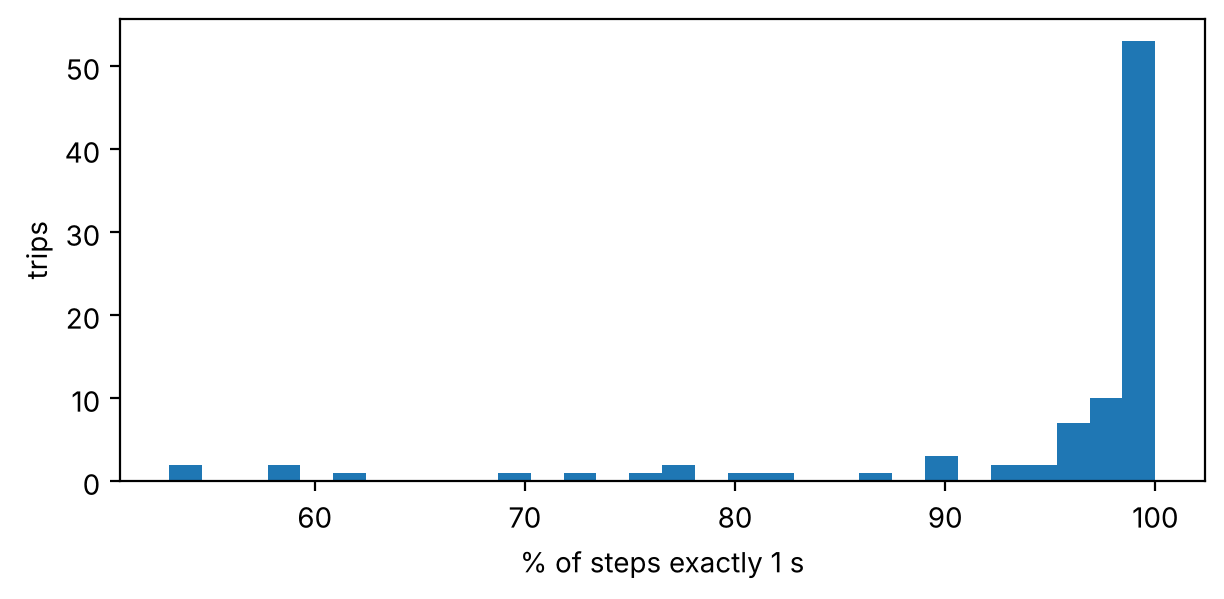

,partition,trip_id,nan,bad_lonlat,dup_or_back_ts,pct_1s,max_gap_s
72,train,90,0,0,0,58.130841,153064.0
61,train,78,0,0,0,75.515818,52810.0
55,train,69,0,0,0,98.935140,2658.0
16,train,21,0,0,0,99.961982,2161.0
8,train,11,0,0,0,99.964627,909.0


In [4]:
plt.figure(figsize=(7, 3)); plt.hist(q.pct_1s, bins=30); plt.xlabel("% of steps exactly 1 s"); plt.ylabel("trips"); plt.show()
q.sort_values("max_gap_s", ascending=False).head(5)

## 3. Network size and connectivity (each trip has its OWN network)

In [5]:
net = []
for part in ["train", "student_test"]:
    for tid in list_trips(RAW / part):
        t = load_trip(RAW / part, tid); n = len(t["nodes"]); a = t["arcs"]
        g = coo_matrix((np.ones(len(a)), (a[:, 0], a[:, 1])), shape=(n, n))
        nc, lab = connected_components(g, directed=False)
        used = np.zeros(n, bool); used[a.ravel()] = True
        net.append(dict(partition=part, trip_id=tid, nodes=n, arcs=len(a), components=nc,
                        isolated_nodes=int((~used).sum()), largest_comp_pct=np.bincount(lab).max() / n * 100))
net = pd.DataFrame(net); print(net.describe().round(1)); net.head()

       trip_id     nodes      arcs  components  isolated_nodes  \
count     90.0      90.0      90.0        90.0            90.0   
mean      49.3   22490.8   45132.7        37.2             0.0   
std       29.2   30868.5   61920.3        58.1             0.0   
min        0.0     299.0     649.0         1.0             0.0   
25%       25.2    3655.2    7282.8         8.2             0.0   
50%       49.0    9305.0   18761.5        19.0             0.0   
75%       74.8   26296.5   52913.2        40.8             0.0   
max       99.0  155003.0  307392.0       421.0             0.0   

       largest_comp_pct  
count              90.0  
mean               96.8  
std                 3.8  
min                69.3  
25%                96.3  
50%                98.0  
75%                98.7  
max               100.0  


,partition,trip_id,nodes,arcs,components,isolated_nodes,largest_comp_pct
0,train,1,88809,165790,175,0,97.798647
1,train,2,7936,16139,14,0,97.656250
2,train,3,9138,18028,42,0,94.386080
3,train,4,7350,15499,12,0,98.693878
4,train,5,898,1579,3,0,98.886414


## 4. GPS trajectory plots (projected to per-trip UTM, metres)

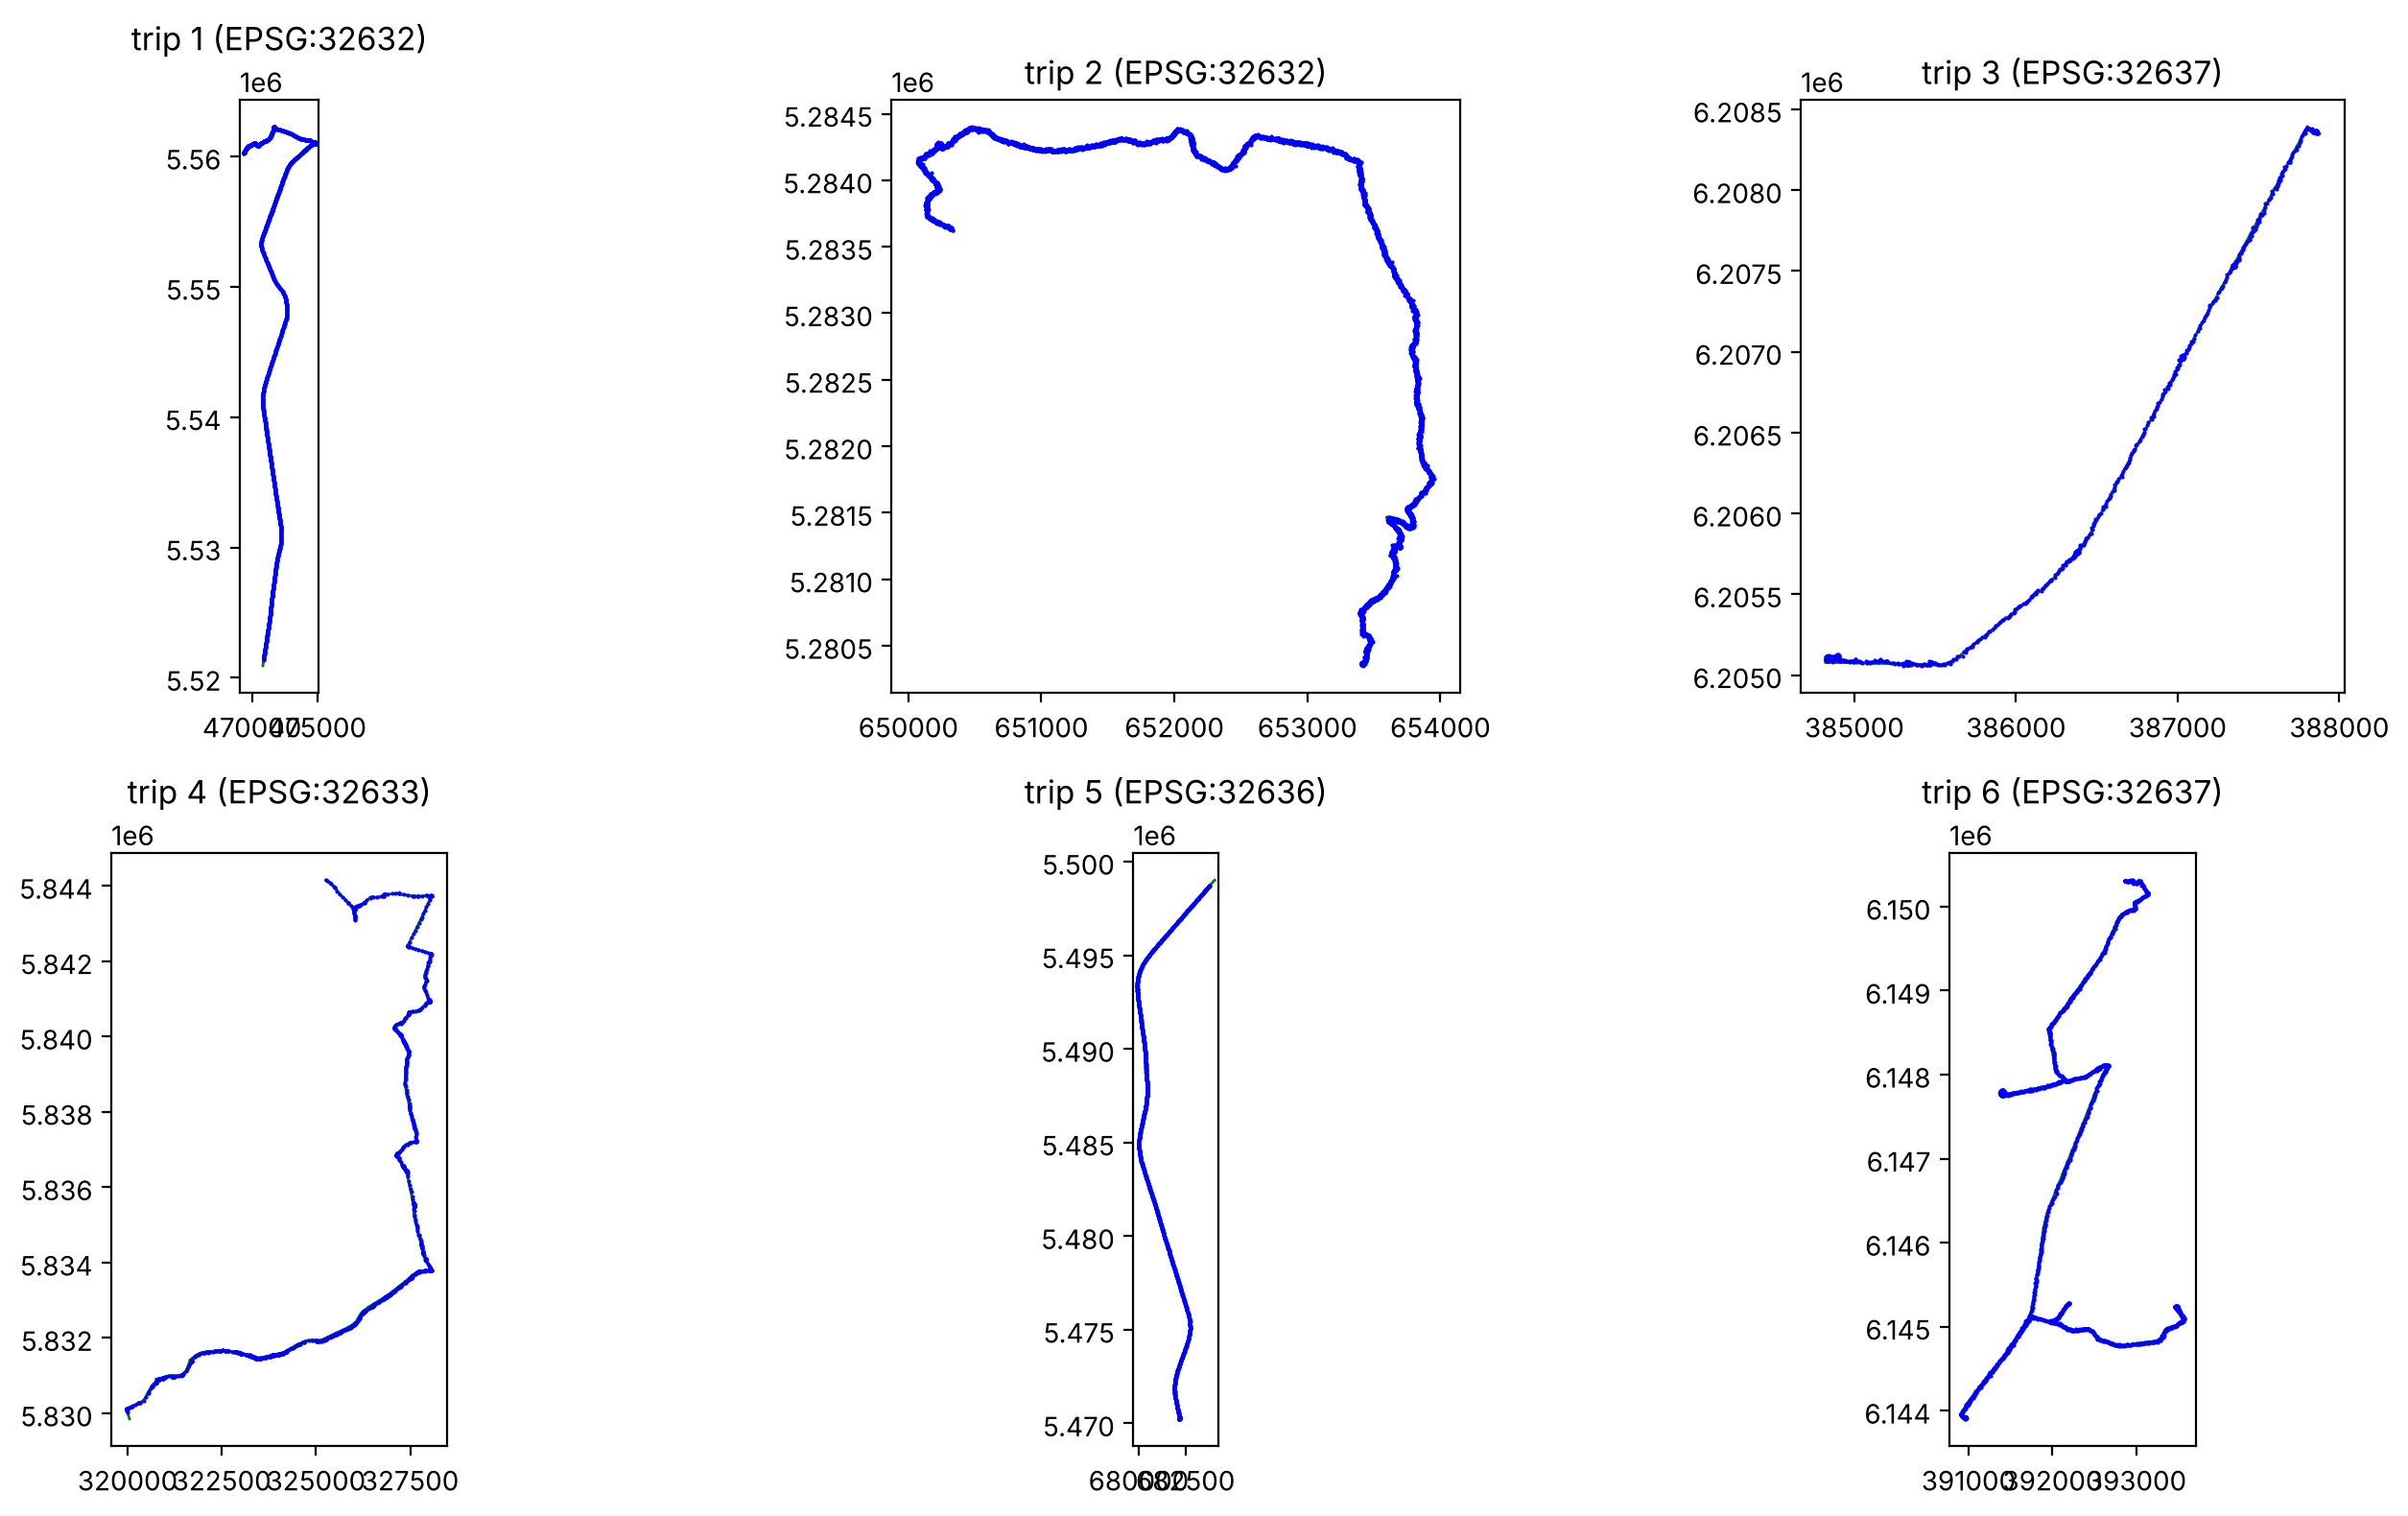

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for a, tid in zip(ax.ravel(), list_trips(RAW / "train")[:6]):
    t = load_trip(RAW / "train", tid); xy, _, A, B, epsg = prepare(t)
    r = t["route"]
    for i in r: a.plot([A[i, 0], B[i, 0]], [A[i, 1], B[i, 1]], "g-", lw=1)
    a.plot(xy[:, 0], xy[:, 1], ".", ms=1, c="b"); a.set_title(f"trip {tid} (EPSG:{epsg})"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

## 5. Route vs track coverage (KEY finding)
The `.route` is a list of arcs, not a label per point, and it often covers only PART of the track.

In [7]:
cov = []
for tid in list_trips(RAW / "train"):
    t = load_trip(RAW / "train", tid); xy, _, A, B, _ = prepare(t); u = np.unique(t["route"]); d = np.empty(len(xy))
    for s in range(0, len(xy), 1000):
        dd, _ = point_segment(xy[s:s+1000, None, :], A[u][None], B[u][None]); d[s:s+1000] = dd.min(1)
    cov.append(dict(trip_id=tid, track_km=np.hypot(*np.diff(xy, axis=0).T).sum() / 1e3,
        route_km=np.hypot(*(B[t["route"]] - A[t["route"]]).T).sum() / 1e3, frac_within_50m=(d < 50).mean()))
cov = pd.DataFrame(cov); print(cov.describe().round(2)); cov.sort_values("frac_within_50m").head(6)

       trip_id  track_km  route_km  frac_within_50m
count    80.00     80.00     80.00            80.00
mean     49.54     37.27     27.86             0.98
std      28.95     34.52     25.71             0.12
min       1.00      6.34      5.01             0.13
25%      25.75     12.80      8.93             1.00
50%      47.50     24.05     14.31             1.00
75%      74.25     48.80     39.40             1.00
max      99.00    169.55     94.34             1.00


,trip_id,track_km,route_km,frac_within_50m
44,54,169.552447,31.418378,0.127582
26,33,47.909111,6.385711,0.410507
1,2,55.944589,7.973523,0.880160
35,43,63.837897,59.301509,0.928079
76,96,71.673923,64.133772,0.955671
53,66,83.328937,73.024540,0.956763


## 6. Folium map: GPS points + road network + reference route

In [8]:
from pyproj import Transformer
tid = list_trips(RAW / "train")[3]; t = load_trip(RAW / "train", tid)
c = t["track"][:, :2].mean(0)
m = folium.Map(location=[c[1], c[0]], zoom_start=14)
lo, hi = t["track"][:, :2].min(0) - .005, t["track"][:, :2].max(0) + .005
nd, ar = t["nodes"], t["arcs"]
inside = ((nd[ar[:, 0]] >= lo) & (nd[ar[:, 0]] <= hi)).all(1)
for a_ in ar[inside][:4000]:
    folium.PolyLine([nd[a_[0]][::-1], nd[a_[1]][::-1]], color="gray", weight=1).add_to(m)
for i in t["route"]:
    folium.PolyLine([nd[ar[i, 0]][::-1], nd[ar[i, 1]][::-1]], color="green", weight=4).add_to(m)
for p in t["track"][::5]:
    folium.CircleMarker([p[1], p[0]], radius=2, color="blue").add_to(m)
Path("reports").mkdir(exist_ok=True); m.save("reports/map_trip.html"); m

## 7. Candidate miss rate (from build_dataset.py)

In [9]:
mr = pd.read_csv("data/processed/candidate_miss_rate.csv")
print(mr.groupby("partition").apply(lambda g: pd.Series({"points": g.n_points.sum(), "labelled": g.n_labelled.sum(),
      "miss_rate": (g.miss_rate_labelled * g.n_labelled).sum() / g.n_labelled.sum()})))
mr.sort_values("miss_rate_labelled", ascending=False).head(5)

                points  labelled  miss_rate
partition                                  
student_test   19160.0   19133.0   0.013275
train         208417.0  185149.0   0.018180


,partition,trip_id,n_points,n_labelled,miss_rate_labelled
26,train,33,5844,2395,0.199582
44,train,54,19313,2039,0.120157
2,train,3,821,821,0.113276
58,train,72,969,969,0.109391
62,train,79,689,689,0.085631


## 8. Data-quality issues and assumptions
1. **Trips are worldwide**: ~23 UTM zones in train. Distances use a UTM zone chosen per trip from its mean longitude (EPSG 326xx/327xx), NOT one fixed EPSG.
2. **Each trip has its own road network**: arc_id/node_id are only valid within a trip.
3. **Route covers only part of the track in many trips** (e.g. trips 54 and 33). Points whose best route arc is >50 m away have no ground truth and are excluded from the labelled parquet (kept in `point_truth.parquet`).
4. **Time gaps**: most trips are ~97-100% 1 s steps but some are much lower (e.g. trip 4 ~54%); features use the real dt.
5. **Arcs are directed**; reverse arcs have identical geometry, so bearing_diff is what separates them.
6. **Labelling assumption**: points are assigned to route arcs monotonically in route order (DP minimising total distance).
7. Stationary points (<1 m move) have no reliable heading: `bearing_diff`=90 and `heading_valid`=0.